# Runner-ups removed from m8x32 refine2

Dictionary 20 is `SOCAL_H_76_230427_014845.x.limited_overlap_k1_w40_pc5_tau04_m8x32_refine2`. For every motif whose median residual gap is below 0.1, its most common runner-up is removed. The residual is the unexplained fraction after the mean plus five components. The gap at a placement is the runner-up residual minus the assigned motif's residual.

Ten motifs are removed: 20, 21, 27, 28, 31, 32, 33, 41, 46, and 49. The reduced dictionary has 25 motifs. Their atoms and placements are unchanged. Placements of the removed motifs are dropped.

Output directory: `/home/yfreund/whale_processing/result/LeiData/SOCAL_H_76_230427_014845.x.limited_overlap_m8x32_refine2_drop_runners`.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from analysis.GPL_Python.gpl_outputs import display_from_spwhiten
from analysis.dict_learning.code.io import discover_windows
from analysis.evaluation.core import (
    _dot_products,
    _load_basis,
    _peak_ratios,
    _residual_summary,
    _specificity_p90,
)

OUT = Path(
    "/home/yfreund/whale_processing/result/LeiData/"
    "SOCAL_H_76_230427_014845.x.limited_overlap_m8x32_refine2_drop_runners"
)
GPL = Path(
    "/home/yfreund/whale_processing/result/LeiData/"
    "SOCAL_H_76_230427_014845.x.gpl/output/spectrogram_npy"
)
summary = json.loads((OUT / "summary.json").read_text())
matchings = json.loads((OUT / "matchings.json").read_text())
counts = np.load(OUT / "counts.npz")
windows = discover_windows(GPL)
windows.sort(key=lambda window: (window.start_sample, window.window_id))
sec_per_bin = float(windows[0].overlap) / float(windows[0].sample_freq)
knobs = summary["knobs"]

offsets = {}
parts = []
cursor = 0
for window in windows:
    data = np.asarray(window.data, dtype=np.float64)
    offsets[window.window_id] = cursor
    parts.append(data)
    cursor += data.shape[1]
spectrogram = np.concatenate(parts, axis=1)

freq_axis = np.linspace(0.0, float(windows[0].sample_freq) / 2.0, int(windows[0].fftl) // 2)
i0 = int(np.argmin(np.abs(freq_axis - float(windows[0].start_freq))))
freqs = freq_axis[i0 : i0 + spectrogram.shape[0]]
band = np.flatnonzero(freqs <= 1500.0)
band_lo, band_hi = int(band[0]), int(band[-1]) + 1
f_lo, f_hi = float(freqs[band_lo]), float(freqs[band_hi - 1])

counts_kept = [row["n_placements"] for row in summary["motifs"]]
ratio = max(counts_kept) / min(counts_kept)
print(f"removed {summary['dropped_motifs']}")
print(
    f"coverage {summary['coverage']:.3f}  "
    f"({summary['n_bins_covered']} / {summary['n_bins_total']} columns)  "
    f"motifs {summary['n_motifs']}  placements {summary['n_placements']}  "
    f"max count {summary['max_count']}"
)
print(f"placement counts {min(counts_kept)} to {max(counts_kept)}  ratio {ratio:.3f}")


removed [20, 21, 27, 28, 31, 32, 33, 41, 46, 49]
coverage 0.501  (9151 / 18270 columns)  motifs 25  placements 861  max count 1
placement counts 10 to 50  ratio 5.000


## Residual and runner-up

Each remaining motif is scored again against the reduced dictionary. The runner-up is the other motif that still remains and has the smallest residual. The median residual and the median gap are taken over the motif's own placements. The runner-up column is the motif that fills that role most often.


In [2]:
models = {row["motif_id"]: _load_basis(str(OUT / row["path"])) for row in summary["motifs"]}
widths = {row["motif_id"]: int(row["width"]) for row in summary["motifs"]}
placements = [
    (row["motif_id"], offsets[row["window_id"]] + int(row["t_start"]), widths[row["motif_id"]])
    for row in matchings
]
scored = _residual_summary(spectrogram, offsets, placements, models)
print(
    f"coverage ratio {scored['coverage_ratio']:.3f}  "
    f"placement ratio {scored['placement_ratio']:.3f}  "
    f"minimum mean gap {scored['min_gap']:.3f}"
)
print(f"{'motif':>6} {'n':>4} {'median residual':>16} {'median gap':>12} {'runner-up':>10}")
for motif_id, row in sorted(scored["motifs"].items()):
    print(
        f"{motif_id:6d} {row['n_placements']:4d} "
        f"{row['residual_median']:16.4f} {row['gap_median']:12.4f} {row['runner_id']:10d}"
    )
below = [motif_id for motif_id, row in scored["motifs"].items() if row["gap_median"] < 0.1]
print(f"motifs with median gap below 0.1: {sorted(below)}")


coverage ratio 3.900  placement ratio 5.000  minimum mean gap 0.045
 motif    n  median residual   median gap  runner-up
     0   28           0.1966       0.6052          1
     1   50           0.2508       0.3782         43
     3   42           0.2509       0.0425         29
    10   12           0.1399       0.5910          3
    11   10           0.1004       0.6294         40
    13   11           0.2661       0.4402         36
    14   21           0.2749       0.4157          1
    17   18           0.1081       0.5222          3
    18   41           0.2022       0.0132         19
    19   44           0.2029       0.0137         18
    22   40           0.2040       0.0142         24
    23   33           0.2061       0.0142         25
    24   43           0.2049       0.0134         19
    25   42           0.2065       0.0152         19
    26   44           0.2100       0.0112         24
    29   38           0.2039       0.0158         19
    30   44           0.2132   

## How many times each column is covered

A column is covered once or not at all. Coverage is the fraction of columns with count 1.


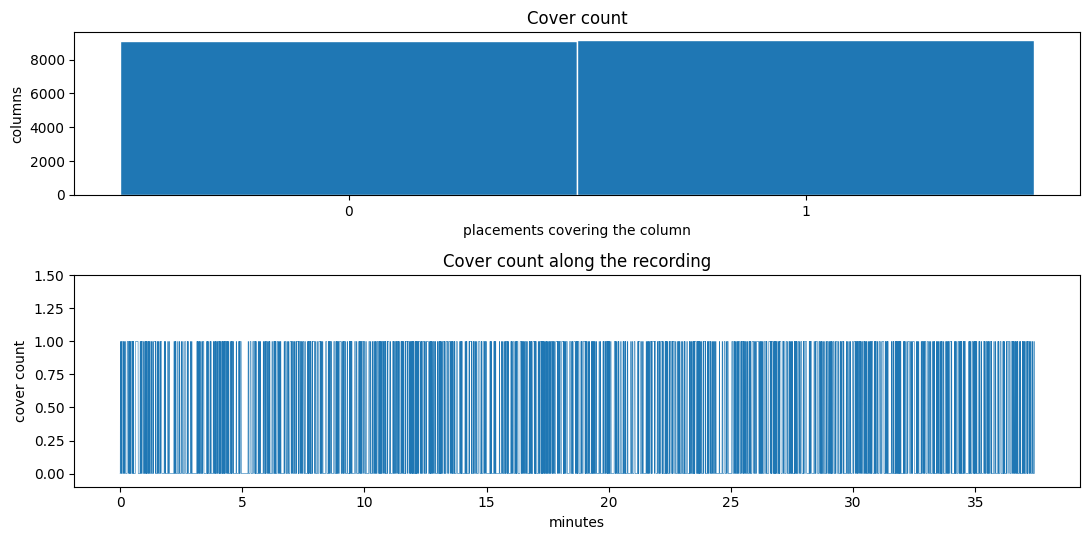

count 0: 9119 columns
count 1: 9151 columns


In [3]:
stacked = np.concatenate([counts[window.window_id] for window in windows])
minutes = np.arange(stacked.size) * sec_per_bin / 60.0
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), gridspec_kw={"height_ratios": [1, 1.3]})
axes[0].hist(stacked, bins=np.arange(-0.5, 2.5, 1), color="C0", edgecolor="white")
axes[0].set_xticks([0, 1])
axes[0].set_xlabel("placements covering the column")
axes[0].set_ylabel("columns")
axes[0].set_title("Cover count")
axes[1].plot(minutes, stacked, color="C0", lw=0.4)
axes[1].set_xlabel("minutes")
axes[1].set_ylabel("cover count")
axes[1].set_ylim(-0.1, 1.5)
axes[1].set_title("Cover count along the recording")
fig.tight_layout()
plt.show()
for value in (0, 1):
    print(f"count {value}: {int(np.sum(stacked == value))} columns")


## Placements per motif


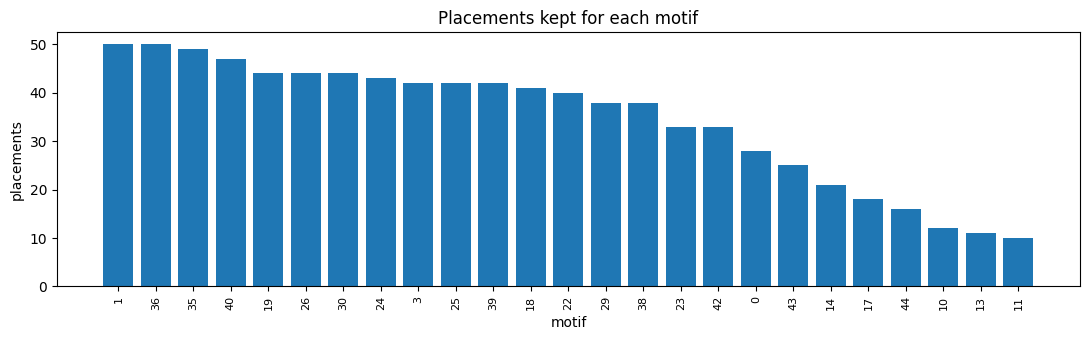

In [4]:
motifs = sorted(summary["motifs"], key=lambda row: -row["n_placements"])
names = [str(row["motif_id"]) for row in motifs]
heights = [row["n_placements"] for row in motifs]
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(np.arange(len(names)), heights, color="C0")
ax.set_xticks(np.arange(len(names)), names, rotation=90, fontsize=8)
ax.set_xlabel("motif")
ax.set_ylabel("placements")
ax.set_title("Placements kept for each motif")
fig.tight_layout()
plt.show()


## Specificity

The dot-product sequence is shifted and scaled by a one-minute Gaussian before the peaks are measured. The number for a motif is the 90th percentile of its peak-to-baseline ratios. The kernel is the leading component.


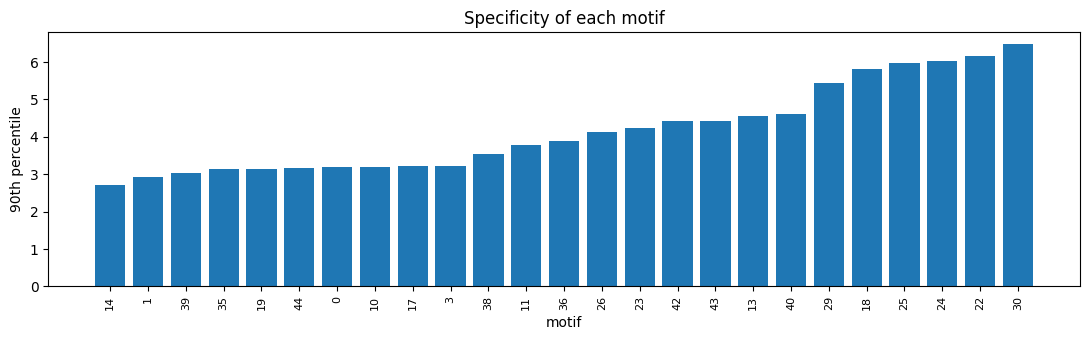

p90  min 2.716  max 6.472


In [5]:
shift_sigma = 60.0 / sec_per_bin
spec_rows = []
for row in summary["motifs"]:
    kernel = np.load(OUT / row["path"])
    if kernel.ndim == 3:
        kernel = kernel[0]
    ratios, percentile = _specificity_p90(
        _peak_ratios(_dot_products(spectrogram, kernel), float(row["width"] // 2), shift_sigma)
    )
    spec_rows.append((row["motif_id"], percentile))
spec_rows.sort(key=lambda item: item[1])
labels = [str(motif_id) for motif_id, _percentile in spec_rows]
p90 = [float(percentile) for _motif_id, percentile in spec_rows]
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(np.arange(len(labels)), p90, color="C0")
ax.set_xticks(np.arange(len(labels)), labels, rotation=90, fontsize=8)
ax.set_xlabel("motif")
ax.set_ylabel("90th percentile")
ax.set_title("Specificity of each motif")
fig.tight_layout()
plt.show()
print(f"p90  min {min(p90):.3f}  max {max(p90):.3f}")


## Motifs

Each panel is the leading principal component, from about 12 Hz to 1500 Hz. The title is the motif index and how many placements it kept.


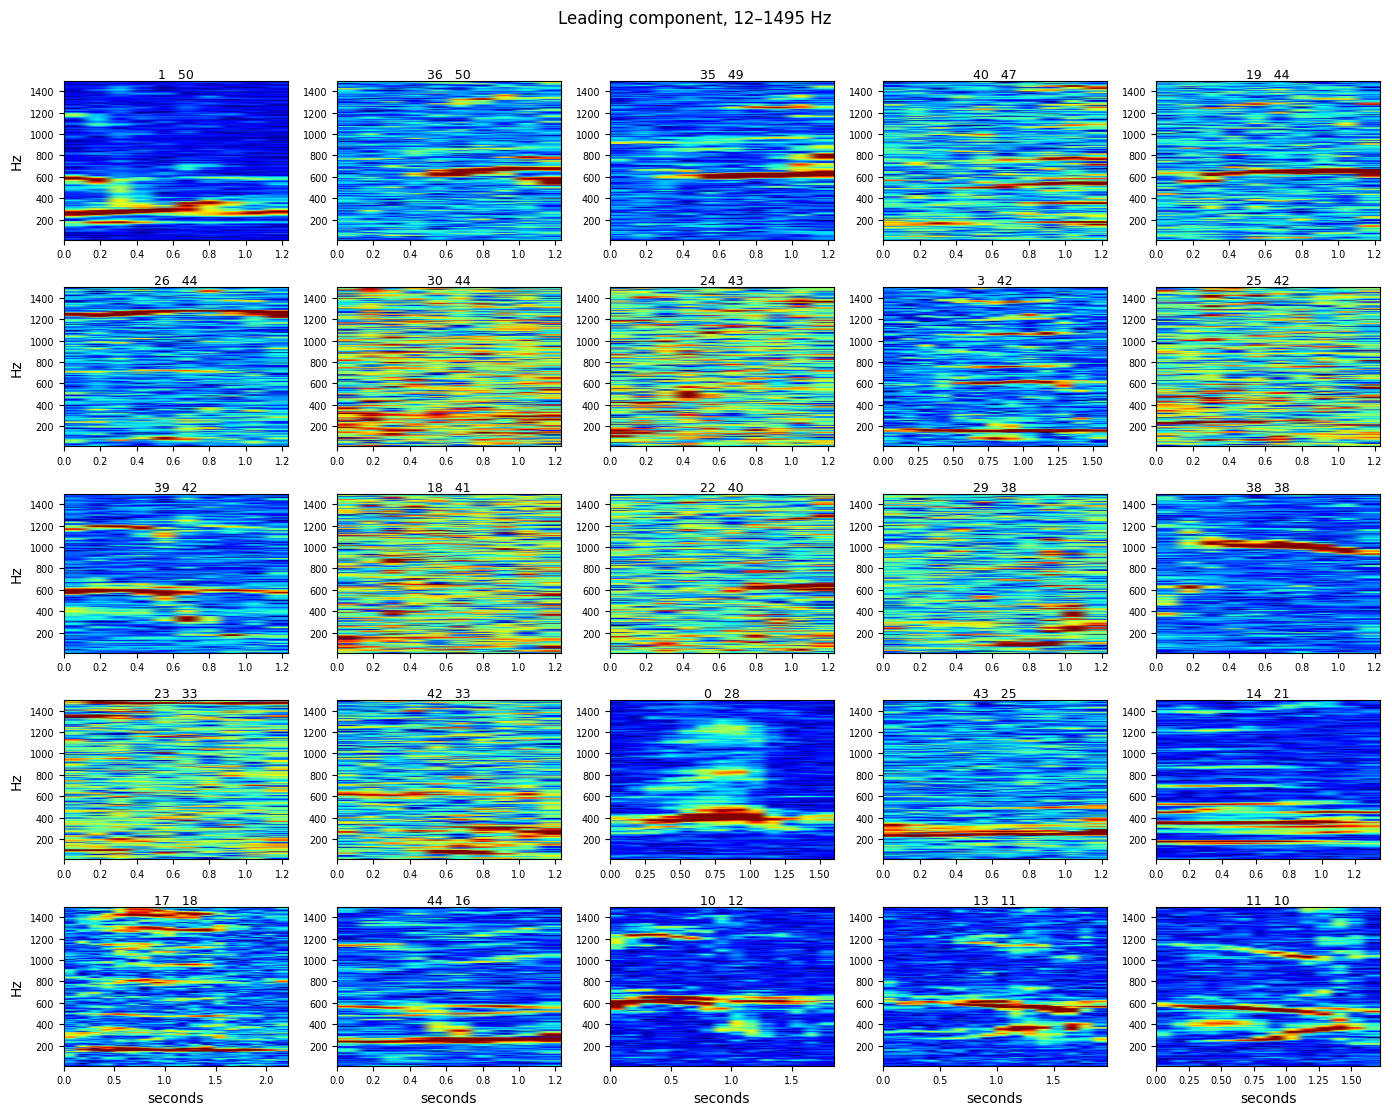

In [6]:
ncols = 5
nrows = int(np.ceil(len(motifs) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 2.2 * nrows))
axes = np.atleast_2d(axes)
for panel, row in enumerate(motifs):
    r, c = divmod(panel, ncols)
    ax = axes[r, c]
    atom = np.load(OUT / row["path"])
    component = atom[0] if atom.ndim == 3 else atom
    shown = display_from_spwhiten(component)[band_lo:band_hi]
    lo, hi = np.percentile(shown, [2, 98])
    extent = [0.0, component.shape[1] * sec_per_bin, f_lo, f_hi]
    ax.imshow(shown, origin="lower", aspect="auto", cmap="jet", vmin=lo, vmax=hi, extent=extent)
    ax.set_title(f"{row['motif_id']}   {row['n_placements']}", fontsize=9, pad=2)
    ax.tick_params(labelsize=7)
    if c == 0:
        ax.set_ylabel("Hz")
    if r == nrows - 1:
        ax.set_xlabel("seconds")
for panel in range(len(motifs), nrows * ncols):
    r, c = divmod(panel, ncols)
    axes[r, c].axis("off")
fig.suptitle(f"Leading component, {f_lo:.0f}–{f_hi:.0f} Hz", y=1.01)
fig.tight_layout()
plt.show()
